## Load data

In [1]:
import pandas as pd
from pathlib import Path

data_file = Path("datasets/winemag-data-130k-v2.csv")
if not data_file.exists():
    data_file = "https://raw.githubusercontent.com/dylanhernandez1/DATA4401_Project3/main/datasets/winemag-data-130k-v2.csv"

df = pd.read_csv(data_file, index_col=0)
print(f"Rows: {len(df):,}")
df[["description", "taster_name", "title"]].head()

Rows: 129,971


,description,taster_name,title
0,"Aromas include tropical fruit, broom, brimston...",Kerin O’Keefe,Nicosia 2013 Vulkà Bianco (Etna)
1,"This is ripe and fruity, a wine that is smooth...",Roger Voss,Quinta dos Avidagos 2011 Avidagos Red (Douro)
2,"Tart and snappy, the flavors of lime flesh and...",Paul Gregutt,Rainstorm 2013 Pinot Gris (Willamette Valley)
3,"Pineapple rind, lemon pith and orange blossom ...",Alexander Peartree,St. Julian 2013 Reserve Late Harvest Riesling ...
4,"Much like the regular bottling from 2012, this...",Paul Gregutt,Sweet Cheeks 2012 Vintner's Reserve Wild Child...


## Missing values

In [2]:
df.isna().sum().to_frame("missing")

,missing
country,63
description,0
designation,37465
points,0
price,8996
province,63
region_1,21247
region_2,79460
taster_name,26244
taster_twitter_handle,31213


## Duplicate reviews

In [3]:
duplicates = df.duplicated(subset=["title", "description"]).sum()
print(f"Duplicate title/review pairs: {duplicates:,}")

Duplicate title/review pairs: 9,983


## Reviews per reviewer

In [4]:
df["taster_name"].value_counts().to_frame("reviews")

,reviews
taster_name,
Roger Voss,25514
Michael Schachner,15134
Kerin O’Keefe,10776
Virginie Boone,9537
Paul Gregutt,9532
Matt Kettmann,6332
Joe Czerwinski,5147
Sean P. Sullivan,4966
Anna Lee C. Iijima,4415


## Vintage and relative year

In [5]:
eda = df.dropna(subset=["description", "taster_name"]).copy()
eda["vintage"] = pd.to_numeric(
    eda["title"].str.extract(r"\b((?:19|20)\d{2})\b")[0], errors="coerce"
).astype("Int64")
print(f"Reviews without an extracted vintage: {eda['vintage'].isna().sum():,}")

# Shared modern window; keep the earliest copy of repeated review text.
eda = eda[eda["vintage"].between(2010, 2016)].sort_values("vintage")
eda = eda.drop_duplicates(subset="description").copy()

# Year 0 = each reviewer's first included vintage with at least 30 reviews.
coverage = eda.groupby(["taster_name", "vintage"]).size().reset_index(name="reviews")
first_vintage = coverage[coverage["reviews"] >= 30].groupby("taster_name")["vintage"].min()
eda["relative_year"] = eda["vintage"] - eda["taster_name"].map(first_vintage)
eda = eda[eda["relative_year"] >= 0].copy()
eda["relative_year"] = eda["relative_year"].astype(int)

eda.groupby("taster_name").agg(
    reviews=("description", "size"),
    first_relative_year=("relative_year", "min"),
    last_relative_year=("relative_year", "max")
).sort_values("reviews", ascending=False)

Reviews without an extracted vintage: 3,542


,reviews,first_relative_year,last_relative_year
taster_name,,,
Roger Voss,16501,0,6
Michael Schachner,8545,0,6
Kerin O’Keefe,8245,0,6
Virginie Boone,7933,0,6
Matt Kettmann,5607,0,6
Paul Gregutt,5071,0,6
Sean P. Sullivan,4319,0,6
Jim Gordon,3587,0,6
Anna Lee C. Iijima,3408,0,6


## Reviews by relative year

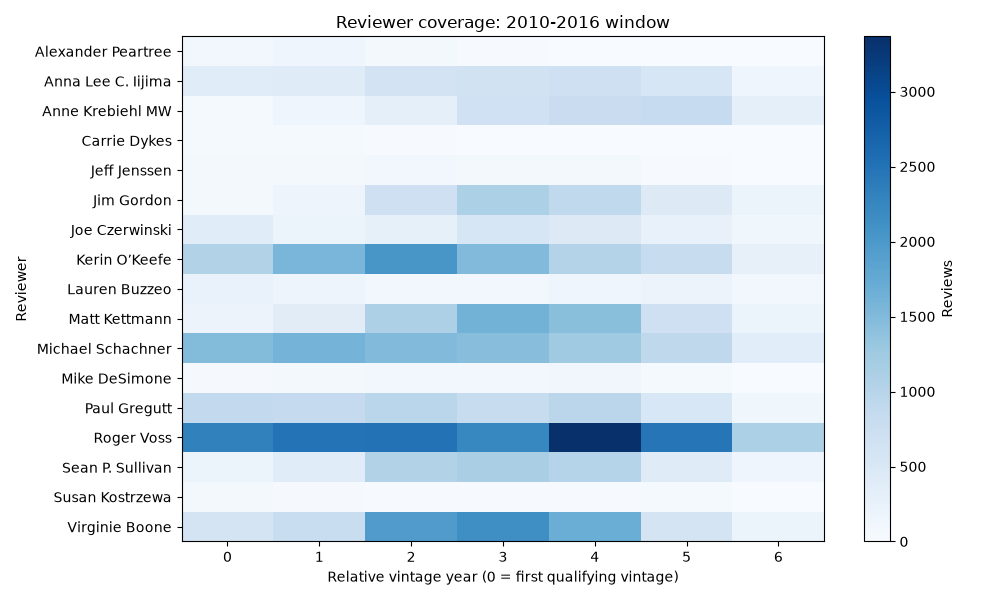

In [6]:
import matplotlib.pyplot as plt

reviewer_year = pd.crosstab(eda["taster_name"], eda["relative_year"])
fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(reviewer_year, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(reviewer_year.columns)), reviewer_year.columns)
ax.set_yticks(range(len(reviewer_year.index)), reviewer_year.index)
ax.set(xlabel="Relative vintage year (0 = first qualifying vintage)", ylabel="Reviewer", title="Reviewer coverage: 2010-2016 window")
fig.colorbar(image, ax=ax, label="Reviews")
plt.tight_layout()
plt.show()

## Review length

In [7]:
eda["word_count"] = eda["description"].str.split().str.len()
eda.groupby("taster_name")["word_count"].agg(["mean", "median"]).round(1).sort_values("mean", ascending=False)

,mean,median
taster_name,,
Matt Kettmann,48.1,48.0
Lauren Buzzeo,47.9,44.0
Anne Krebiehl MW,46.8,44.0
Mike DeSimone,45.7,46.0
Carrie Dykes,43.0,42.0
Paul Gregutt,41.6,40.0
Joe Czerwinski,41.0,40.0
Michael Schachner,40.4,40.0
Virginie Boone,40.0,40.0


## Common words

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

# Start with the five reviewers who have the most data.
top_reviewers = eda["taster_name"].value_counts().head(5).index
common_words = {}

for reviewer in top_reviewers:
    text = eda.loc[eda["taster_name"].eq(reviewer), "description"]
    vectorizer = CountVectorizer(stop_words="english")
    counts = vectorizer.fit_transform(text)
    totals = pd.Series(counts.sum(axis=0).A1, index=vectorizer.get_feature_names_out())
    common_words[reviewer] = ", ".join(totals.nlargest(10).index)

pd.Series(common_words, name="top_10_words").to_frame()

,top_10_words
Roger Voss,"wine, drink, acidity, ripe, fruits, fruit, tan..."
Michael Schachner,"flavors, aromas, finish, palate, berry, plum, ..."
Kerin O’Keefe,"palate, aromas, tannins, cherry, black, offers..."
Virginie Boone,"wine, oak, black, finish, fruit, cherry, bodie..."
Matt Kettmann,"palate, nose, flavors, black, aromas, bottling..."


## Reviewer specialties and Napa counts

In [9]:
from IPython.display import display

specialties = eda.groupby("taster_name")[["country", "region_1", "variety"]].agg(
    lambda values: ", ".join(values.value_counts().head(3).index)
)
display(specialties.loc[top_reviewers].rename(columns={
    "country": "top_countries", "region_1": "top_regions", "variety": "top_varieties"
}))

napa = eda[eda["region_2"].eq("Napa") | eda["region_1"].eq("Napa Valley")]
display(napa["taster_name"].value_counts().to_frame("napa_reviews"))

,top_countries,top_regions,top_varieties
taster_name,,,
Roger Voss,"France, Portugal, Austria","Côtes de Provence, Alsace, Sancerre","Bordeaux-style Red Blend, Chardonnay, Portugue..."
Michael Schachner,"Spain, Chile, Argentina","Mendoza, Rioja, Ribera del Duero","Malbec, Cabernet Sauvignon, Red Blend"
Kerin O’Keefe,Italy,"Barolo, Chianti Classico, Brunello di Montalcino","Red Blend, Nebbiolo, Sangiovese"
Virginie Boone,US,"Napa Valley, Russian River Valley, Sonoma Coast","Pinot Noir, Cabernet Sauvignon, Chardonnay"
Matt Kettmann,"US, Chile","Paso Robles, Sta. Rita Hills, Santa Barbara Co...","Pinot Noir, Chardonnay, Syrah"


,napa_reviews
taster_name,
Virginie Boone,2549
Jim Gordon,31
Matt Kettmann,5


## Word use over time

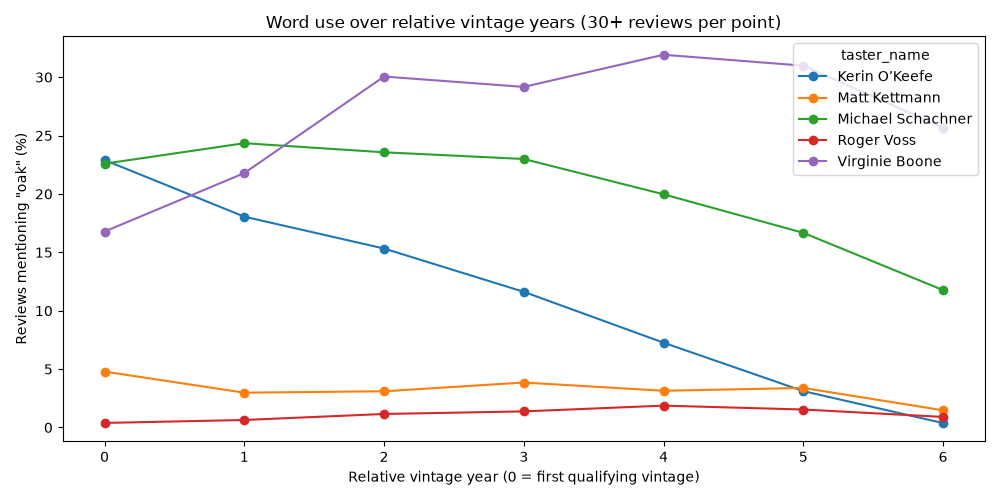

In [10]:
# Example: percentage of reviews mentioning "oak". Change the word to explore others.
word = "oak"
word_trends = eda.assign(
    mentions_word=eda["description"].str.contains(rf"\b{word}\b", case=False, na=False)
).groupby(["taster_name", "relative_year"]).agg(
    reviews=("description", "size"), mention_rate=("mentions_word", "mean")
).reset_index()

word_trends = word_trends[
    word_trends["taster_name"].isin(top_reviewers) & (word_trends["reviews"] >= 30)
]
trend_table = word_trends.pivot(index="relative_year", columns="taster_name", values="mention_rate") * 100
trend_table.plot(figsize=(10, 5), marker="o")
plt.xlabel("Relative vintage year (0 = first qualifying vintage)")
plt.ylabel(f'Reviews mentioning "{word}" (%)')
plt.title("Word use over relative vintage years (30+ reviews per point)")
plt.tight_layout()
plt.show()

## Three-reviewer dataset

In [11]:
reviewers = ["Paul Gregutt", "Virginie Boone", "Matt Kettmann"]
model_df = eda.loc[
    eda["taster_name"].isin(reviewers),
    ["description", "taster_name", "vintage", "relative_year"]
].copy()
model_df = model_df[model_df["description"].str.strip().ne("")]

pd.crosstab(model_df["taster_name"], model_df["vintage"])

vintage,2010,2011,2012,2013,2014,2015,2016
taster_name,,,,,,,
Matt Kettmann,188,369,1096,1610,1431,709,204
Paul Gregutt,877,850,965,791,949,515,124
Virginie Boone,596,785,1950,2143,1695,581,183


## Chronological split

In [12]:
# Vintage orders the split; neither vintage nor relative year is a predictor.
train = model_df[model_df["vintage"] <= 2012].copy()
validation = model_df[model_df["vintage"] == 2013].copy()
test = model_df[model_df["vintage"] == 2014].copy()
# The later comparison below also evaluates 2015-2016.

pd.DataFrame({
    "train_2010_2012": train["taster_name"].value_counts(),
    "validation_2013": validation["taster_name"].value_counts(),
    "test_2014": test["taster_name"].value_counts()
}).reindex(reviewers).fillna(0).astype(int)

,train_2010_2012,validation_2013,test_2014
taster_name,,,
Paul Gregutt,2692,791,949
Virginie Boone,3331,2143,1695
Matt Kettmann,1653,1610,1431


## TF-IDF + logistic regression

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=10000),
    LogisticRegression(max_iter=1000)
)
# Learn the vocabulary and model from training reviews only.
model.fit(train["description"], train["taster_name"]);

## Results

In [14]:
from sklearn.metrics import accuracy_score, f1_score

majority_reviewer = train["taster_name"].mode().iloc[0]
results = []
for split_name, data in [("Train (2010-2012)", train), ("Validation (2013)", validation), ("Test (2014)", test)]:
    actual = data["taster_name"]
    predictions = model.predict(data["description"])
    for name, predicted in [
        ("Majority baseline", [majority_reviewer] * len(data)),
        ("TF-IDF + logistic regression", predictions)
    ]:
        results.append({
            "split": split_name, "model": name,
            "accuracy": accuracy_score(actual, predicted),
            "macro_f1": f1_score(actual, predicted, average="macro", zero_division=0)
        })

pd.DataFrame(results).round(3)

,split,model,accuracy,macro_f1
0,Train (2010-2012),Majority baseline,0.434,0.202
1,Train (2010-2012),TF-IDF + logistic regression,0.997,0.997
2,Validation (2013),Majority baseline,0.472,0.214
3,Validation (2013),TF-IDF + logistic regression,0.990,0.988
4,Test (2014),Majority baseline,0.416,0.196
5,Test (2014),TF-IDF + logistic regression,0.984,0.984


## Test predictions by reviewer

In [15]:
from sklearn.metrics import confusion_matrix

test_predictions = model.predict(test["description"])
pd.DataFrame(
    confusion_matrix(test["taster_name"], test_predictions, labels=reviewers),
    index=pd.Index(reviewers, name="Actual"),
    columns=pd.Index(reviewers, name="Predicted")
)

Predicted,Paul Gregutt,Virginie Boone,Matt Kettmann
Actual,,,
Paul Gregutt,932,17,0
Virginie Boone,18,1667,10
Matt Kettmann,3,16,1412


## Important phrases per reviewer

In [16]:
vectorizer, classifier = model.steps[0][1], model.steps[1][1]
features = vectorizer.get_feature_names_out()

# Largest positive coefficients, not just the most frequent words.
top_phrases = {}
for reviewer, weights in zip(classifier.classes_, classifier.coef_):
    strongest = pd.Series(weights, index=features).nlargest(10)
    top_phrases[reviewer] = [f"{phrase} ({weight:.2f})" for phrase, weight in strongest.items()]

pd.DataFrame(top_phrases, index=range(1, 11))

,Matt Kettmann,Paul Gregutt,Virginie Boone
1,nose (4.87),fruit (3.28),in (4.50)
2,aromas (4.55),flavors (3.08),oak (2.56)
3,palate (3.70),fruits (2.42),soft (2.42)
4,the palate (3.45),flavors of (2.20),its (2.42)
5,aromas of (3.36),fruit flavors (1.99),bodied (2.17)
6,on (2.86),it (1.95),texture (1.98)
7,the nose (2.80),tart (1.76),on the (1.78)
8,on this (2.60),excellent (1.75),taste (1.72)
9,nose of (2.19),cherry fruit (1.74),this wine (1.65)
10,black (2.09),barrel (1.65),tannin (1.65)


## Example predictions and supporting phrases

In [17]:
explained = test.assign(predicted=test_predictions)
examples = pd.concat([
    explained[explained["taster_name"].eq(reviewer) & explained["predicted"].eq(reviewer)].head(1)
    for reviewer in reviewers
] + [explained[explained["taster_name"].ne(explained["predicted"])].head(1)])

explanations = []
for _, review in examples.iterrows():
    class_position = list(classifier.classes_).index(review["predicted"])
    text_features = vectorizer.transform([review["description"]])
    # TF-IDF times coefficient: positive contributions to the predicted class score.
    contributions = text_features.multiply(classifier.coef_[class_position]).toarray().ravel()
    strongest = pd.Series(contributions, index=features)
    strongest = strongest[strongest > 0].nlargest(5)
    explanations.append({
        "actual": review["taster_name"], "predicted": review["predicted"],
        "supporting_phrases": ", ".join(f"{phrase} ({value:.2f})" for phrase, value in strongest.items()),
        "review": review["description"]
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(explanations))

,actual,predicted,supporting_phrases,review
0,Paul Gregutt,Paul Gregutt,"cherry fruit (0.23), it (0.21), fruit (0.21), reserve (0.18), new (0.17)","The Nicholas reserve sees one-third new French oak. It's a mixed-clone vineyard-row selection, with pie-cherry fruit and a dusting of cocoa. It drinks well already, with a smooth well-integrated finish."
1,Virginie Boone,Virginie Boone,"in (0.41), soft (0.21), its (0.21), otherwise (0.15), dried herb (0.13)","There's an intensity of spicy cardamom and dried herb in this wine, otherwise layered in soft, refreshingly dry elements of cranberry and rhubarb. Darker hued than many of its counterparts, it retains a tannic grip to the finish."
2,Matt Kettmann,Matt Kettmann,"aromas (0.37), black (0.27), the palate (0.24), palate (0.24), crushed (0.22)","This hearty, rich bottling needs time to breathe, yielding fragrant black cherry, black currant, cola and roasted fennel aromas as it opens. It's soft and rounded on the palate, its blackberry, cocoa, crushed herb and pepper flavors blanketed in silky tannins."
3,Paul Gregutt,Virginie Boone,"bodied (0.27), big (0.20), approachable (0.13), medium bodied (0.12), medium (0.12)","A big-production, medium-bodied effort, this has noticeable sweetness that softens the acidity. Sweet apple and pear fruit dominate an easy-drinking, approachable, simple but enjoyable Pinot Gris."


## Regional checks: training data only

In [18]:
import re
from sklearn.base import clone

# Region-only baseline: most common training reviewer in each region.
train_region = eda.loc[train.index, "region_2"].fillna("Unknown")
region_counts = pd.crosstab(train_region, train["taster_name"])
region_reviewer = region_counts.idxmax(axis=1)

# Mask known geographic names, using training metadata only.
geo_names = pd.unique(eda.loc[train.index, ["country", "province", "region_1", "region_2"]].to_numpy().ravel())
geo_names = [str(name).strip() for name in geo_names if pd.notna(name) and len(str(name).strip()) >= 3]
geo_names = [name for name in geo_names if name.lower() not in {"other", "unknown"}]
geo_pattern = re.compile(
    r"(?<!\w)(?:" + "|".join(re.escape(name) for name in sorted(geo_names, key=len, reverse=True)) + r")(?!\w)",
    flags=re.IGNORECASE
)

def mask_geography(text):
    return text.str.replace(geo_pattern, " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

masked_model = clone(model)
masked_model.fit(mask_geography(train["description"]), train["taster_name"]);

## Regional comparison

In [19]:
regional_results = []
for split_name, data in [("Validation (2013)", validation), ("Test (2014)", test)]:
    regions = eda.loc[data.index, "region_2"].fillna("Unknown")
    region_predictions = regions.map(region_reviewer).fillna(majority_reviewer)
    for name, predictions in [
        ("Original text", model.predict(data["description"])),
        ("Region only", region_predictions),
        ("Text with geographic names removed", masked_model.predict(mask_geography(data["description"])))
    ]:
        regional_results.append({
            "split": split_name, "model": name,
            "accuracy": accuracy_score(data["taster_name"], predictions),
            "macro_f1": f1_score(data["taster_name"], predictions, average="macro", zero_division=0)
        })

matched = test["description"].str.contains(geo_pattern, regex=True).mean()
print(f"Known geographic names matched in {matched:.1%} of test reviews.")
# Remaining regional grape/flavor clues are not removed by this check.
pd.DataFrame(regional_results).round(3)

Known geographic names matched in 7.9% of test reviews.


,split,model,accuracy,macro_f1
0,Validation (2013),Original text,0.990,0.988
1,Validation (2013),Region only,0.973,0.967
2,Validation (2013),Text with geographic names removed,0.989,0.987
3,Test (2014),Original text,0.984,0.984
4,Test (2014),Region only,0.966,0.963
5,Test (2014),Text with geographic names removed,0.983,0.983


## Original vs yearly updated model

In [20]:
# Same reviewers and settings throughout. No future reviews enter training.
fixed_model = clone(model)
fixed_model.fit(train["description"], train["taster_name"])
vintage_rows = []

for year in range(2013, 2017):
    history = model_df[model_df["vintage"] < year]
    future = model_df[model_df["vintage"] == year]
    updated_model = clone(model)
    updated_model.fit(history["description"], history["taster_name"])
    for name, fitted in [("Original", fixed_model), ("Updated yearly", updated_model)]:
        predictions = fitted.predict(future["description"])
        vintage_rows.append({
            "test_vintage": year, "model": name,
            "training_reviews": len(train) if name == "Original" else len(history),
            "test_reviews": len(future),
            "accuracy": accuracy_score(future["taster_name"], predictions),
            "macro_f1": f1_score(future["taster_name"], predictions, average="macro", zero_division=0)
        })

vintage_results = pd.DataFrame(vintage_rows)
vintage_results.pivot(index="test_vintage", columns="model", values=["accuracy", "macro_f1"]).round(3)

accuracy                macro_f1               
model        Original Updated yearly Original Updated yearly
test_vintage                                                
2013            0.990          0.990    0.988          0.988
2014            0.984          0.992    0.984          0.992
2015            0.971          0.986    0.971          0.985
2016            0.961          0.984    0.959          0.982

## Performance across vintages

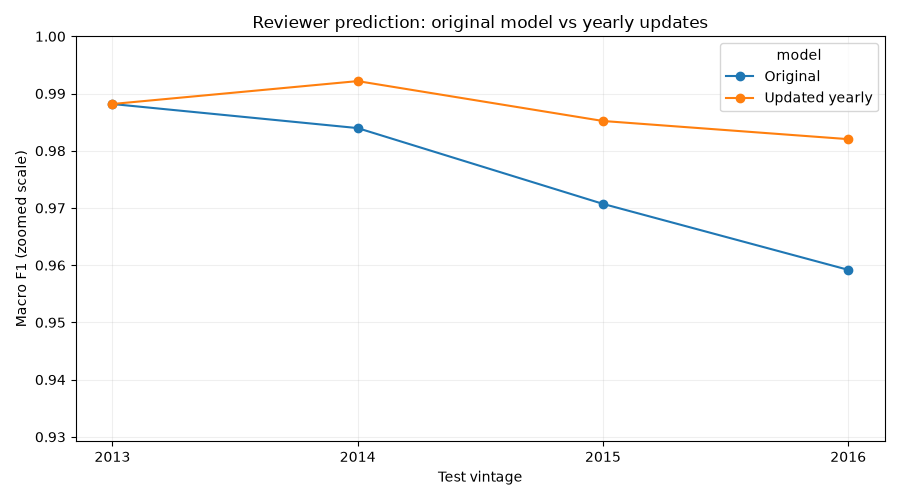

In [21]:
scores = vintage_results.pivot(index="test_vintage", columns="model", values="macro_f1")
scores.plot(figsize=(9, 5), marker="o")
plt.xticks(scores.index)
plt.ylim(max(0, scores.min().min() - 0.03), 1)
plt.xlabel("Test vintage")
plt.ylabel("Macro F1 (zoomed scale)")
plt.title("Reviewer prediction: original model vs yearly updates")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Same region and grape: Alsace Riesling

In [22]:
# Small exploratory control on two different reviewers, not the original three.
matched_pool = eda[eda["region_1"].eq("Alsace") & eda["variety"].eq("Riesling")].copy()
raw_matched_train = matched_pool[matched_pool["vintage"] <= 2012]
raw_matched_test = matched_pool[matched_pool["vintage"] == 2013]
counts = raw_matched_train["taster_name"].value_counts()
matched_reviewers = counts[counts >= 30].index.tolist()

# Equal reviewer counts within each vintage also control vintage composition.
def match_vintages(data):
    groups = []
    for _, vintage_group in data.groupby("vintage"):
        counts = vintage_group["taster_name"].value_counts().reindex(matched_reviewers, fill_value=0)
        n = int(counts.min())
        if n:
            group = vintage_group[vintage_group["taster_name"].isin(matched_reviewers)]
            groups.append(group.groupby("taster_name").sample(n=n, random_state=42))
    return pd.concat(groups)

matched_train = match_vintages(raw_matched_train)
matched_test = match_vintages(raw_matched_test)
pd.DataFrame({
    "available_train_2010_2012": raw_matched_train["taster_name"].value_counts(),
    "available_test_2013": raw_matched_test["taster_name"].value_counts(),
    "matched_train": matched_train["taster_name"].value_counts(),
    "matched_test": matched_test["taster_name"].value_counts()
}).reindex(matched_reviewers).fillna(0).astype(int)

,available_train_2010_2012,available_test_2013,matched_train,matched_test
taster_name,,,,
Roger Voss,149,17,38,17
Anne Krebiehl MW,38,71,38,17


## Matched comparison results: small exploratory sample

In [23]:
matched_model = clone(model)
matched_model.fit(matched_train["description"], matched_train["taster_name"])
matched_predictions = matched_model.predict(matched_test["description"])
matched_majority = matched_train["taster_name"].mode().iloc[0]

matched_rows = []
for name, predictions in [
    ("Majority baseline", [matched_majority] * len(matched_test)),
    ("TF-IDF + logistic regression", matched_predictions)
]:
    matched_rows.append({
        "model": name,
        "accuracy": accuracy_score(matched_test["taster_name"], predictions),
        "macro_f1": f1_score(matched_test["taster_name"], predictions, average="macro", zero_division=0)
    })

print(f"Training reviews: {len(matched_train)}. Test reviews: {len(matched_test)}.")
# Same recorded region, grape and vintage mix; other wine differences can remain.
pd.DataFrame(matched_rows).round(3)

Training reviews: 76. Test reviews: 34.


,model,accuracy,macro_f1
0,Majority baseline,0.5,0.333
1,TF-IDF + logistic regression,1.0,1.000
